# Скользящие средние на 5-минутках NG и BR: полная сетка

Исследование стратегии «цена пересекает быструю среднюю, направление разрешает наклон
медленной». Полная сетка — 98 × 246 периодов × 36 сочетаний типов × 2 метода нейтрали ×
2 модели выхода = **3 471 552 конфигурации на инструмент**; отбор только по in-sample
(до 2024-01-01), проверка — на out-of-sample (2024-01 … 2026-10).

Цифры и выводы — в `docs/RESULTS_MA_CROSSOVER_5M.md`; здесь — девять обязательных
типов графиков и два дополнительных. Ноутбук читает уже посчитанные результаты из
рабочего каталога (`MA5M_WORK`); пересчёт — скрипты в `research/ma_crossover_5m/`.

Цвет: синий — прибыль/«да», красный — убыток/«нет», серый — ноль. Это та же
дивергентная пара, что в ноутбуках 01–02; зелёный против красного не используется,
потому что именно эту пару не различают при дейтеранопии. На картах числа и подписи
дублируют цвет.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in Path.cwd().parents if (p / "research" / "ma_crossover_5m").is_dir())
sys.path.insert(0, str(ROOT / "research" / "ma_crossover_5m"))
import plots as P            # noqa: E402

WORK = Path(os.environ.get("MA5M_WORK", "/home/user/ma5m_work"))
STAGE = os.environ.get("MA5M_STAGE", "stage3")
A = WORK / "analysis"
TYPES = ["SMA", "EMA", "WMA", "SSMA", "VWMA", "TMA"]
FAST = np.arange(2, 100)
SLOW = np.arange(5, 251)
TICKERS = ["NG", "BR"]
NAMES = {"NG": "природный газ", "BR": "Brent"}
meta = {t: json.loads((WORK / STAGE / t / "meta.json").read_text()) for t in TICKERS}
res = {t: json.loads((A / STAGE / t / "results.json").read_text()) for t in TICKERS}
cube = lambda t, c: np.load(A / STAGE / t / f"cube_{c}.npy", mmap_mode="r")
picks = {t: pd.read_csv(A / STAGE / t / "picks.csv") for t in TICKERS}
print("этап:", STAGE, "| конфигураций на инструмент:", f"{res['NG']['n_configs']:,}")
for t in TICKERS:
    print(t, "| IS мес.", res[t]["is_months"], "| OOS мес.", res[t]["oos_months"],
          "| параметры наклона:", meta[t].get("per_method") or {k: meta[t][k] for k in ("k", "coverage", "atr_period")})


этап: stage3 | конфигураций на инструмент: 3,471,552
NG | IS мес. 47 | OOS мес. 34 | параметры наклона: {'A_pct': {'k': 34, 'coverage': 0.4, 'atr_period': 14}, 'B_atr': {'k': 34, 'coverage': 0.25, 'atr_period': 28}}
BR | IS мес. 145 | OOS мес. 34 | параметры наклона: {'A_pct': {'k': 34, 'coverage': 0.6, 'atr_period': 14}, 'B_atr': {'k': 34, 'coverage': 0.4, 'atr_period': 28}}


## 1. Тепловые карты Fast × Slow

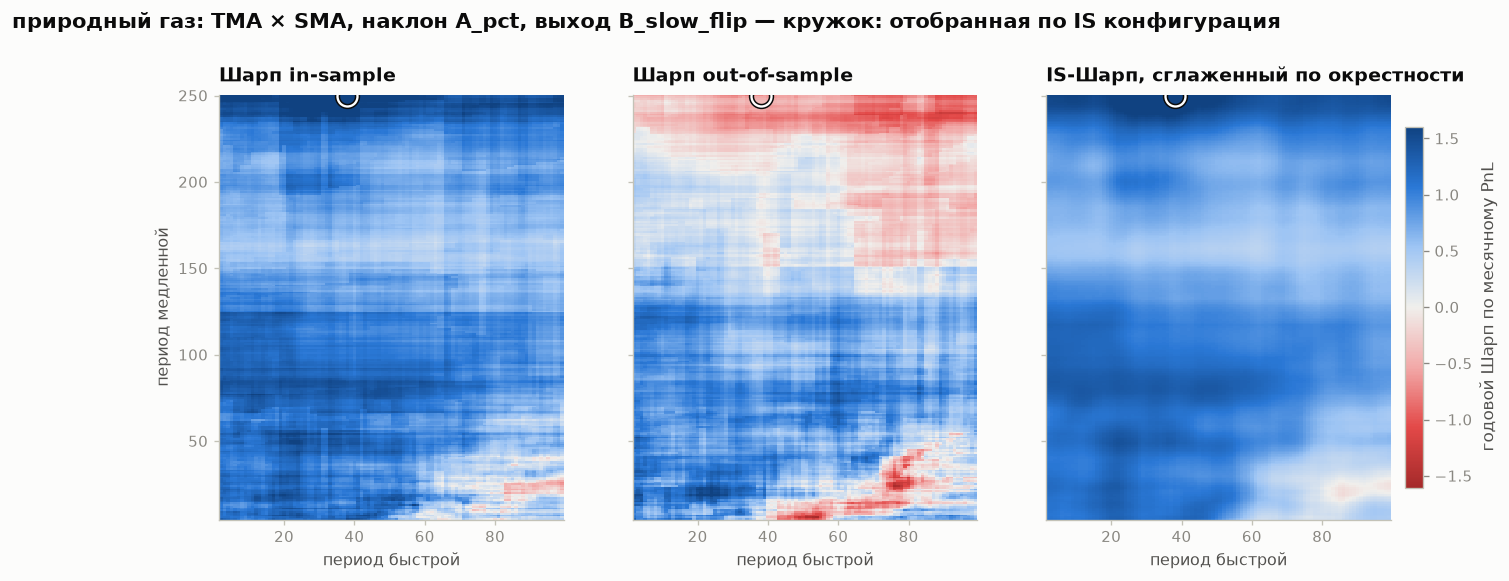

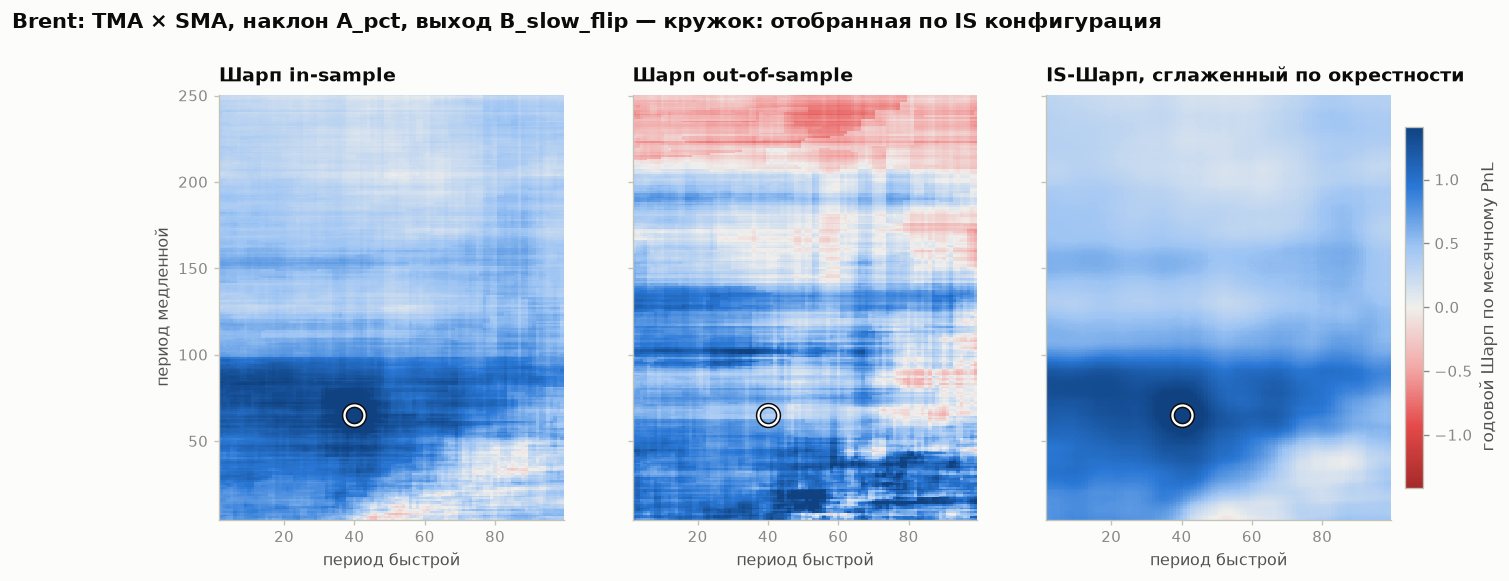

In [2]:
# 1. Тепловые карты Fast × Slow для семейства отобранной стратегии (правило R3,
#    плато in-sample). Три панели на инструмент: IS-Шарп, OOS-Шарп и
#    сглаженный IS-Шарп, по которому шёл отбор. Шкала общая и симметричная.
for t in TICKERS:
    pk = picks[t].query("scope == 'global' and rule == 'R3_plateau'").iloc[0]
    mi = ["A_pct", "B_atr"].index(pk["method"]); ei = ["A_fast_cross", "B_slow_flip"].index(pk["exit"])
    si, fi = TYPES.index(pk["slow_type"]), TYPES.index(pk["fast_type"])
    mats = {c: np.asarray(cube(t, c)[mi, si, :, ei, fi, :]) for c in ("sharpe_m_is", "sharpe_m_oos", "plateau_sharpe_is")}
    norm = P.sym_norm(np.concatenate([m.ravel() for m in mats.values()]))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
    titles = {"sharpe_m_is": "Шарп in-sample", "sharpe_m_oos": "Шарп out-of-sample",
              "plateau_sharpe_is": "IS-Шарп, сглаженный по окрестности"}
    for ax, (c, m) in zip(axes, mats.items()):
        im = P.heatmap(ax, m, FAST, SLOW, norm=norm, title=titles[c],
                       xlabel="период быстрой", ylabel="период медленной" if c == "sharpe_m_is" else "",
                       mark=(pk["fast_period"], pk["slow_period"]))
    cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.01); cb.set_label("годовой Шарп по месячному PnL", color=P.INK_2)
    fig.suptitle(f"{NAMES[t]}: {pk['fast_type']} × {pk['slow_type']}, наклон {pk['method']}, выход {pk['exit']}"
                 f" — кружок: отобранная по IS конфигурация", x=0.01, ha="left", color=P.INK, fontsize=12.5,
                 fontweight="bold", y=1.03)
    plt.show()


## 2. Все 36 сочетаний типов средних

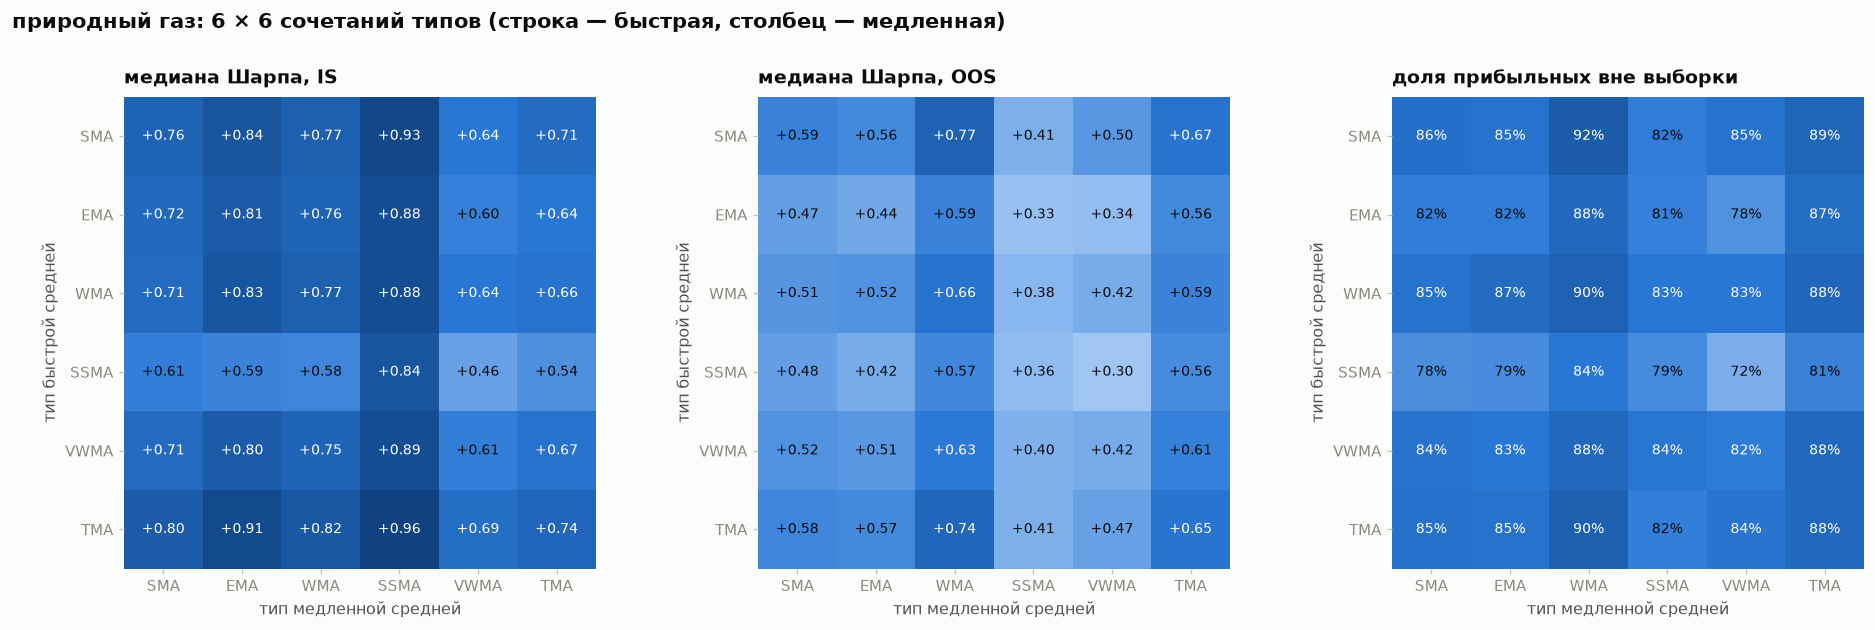

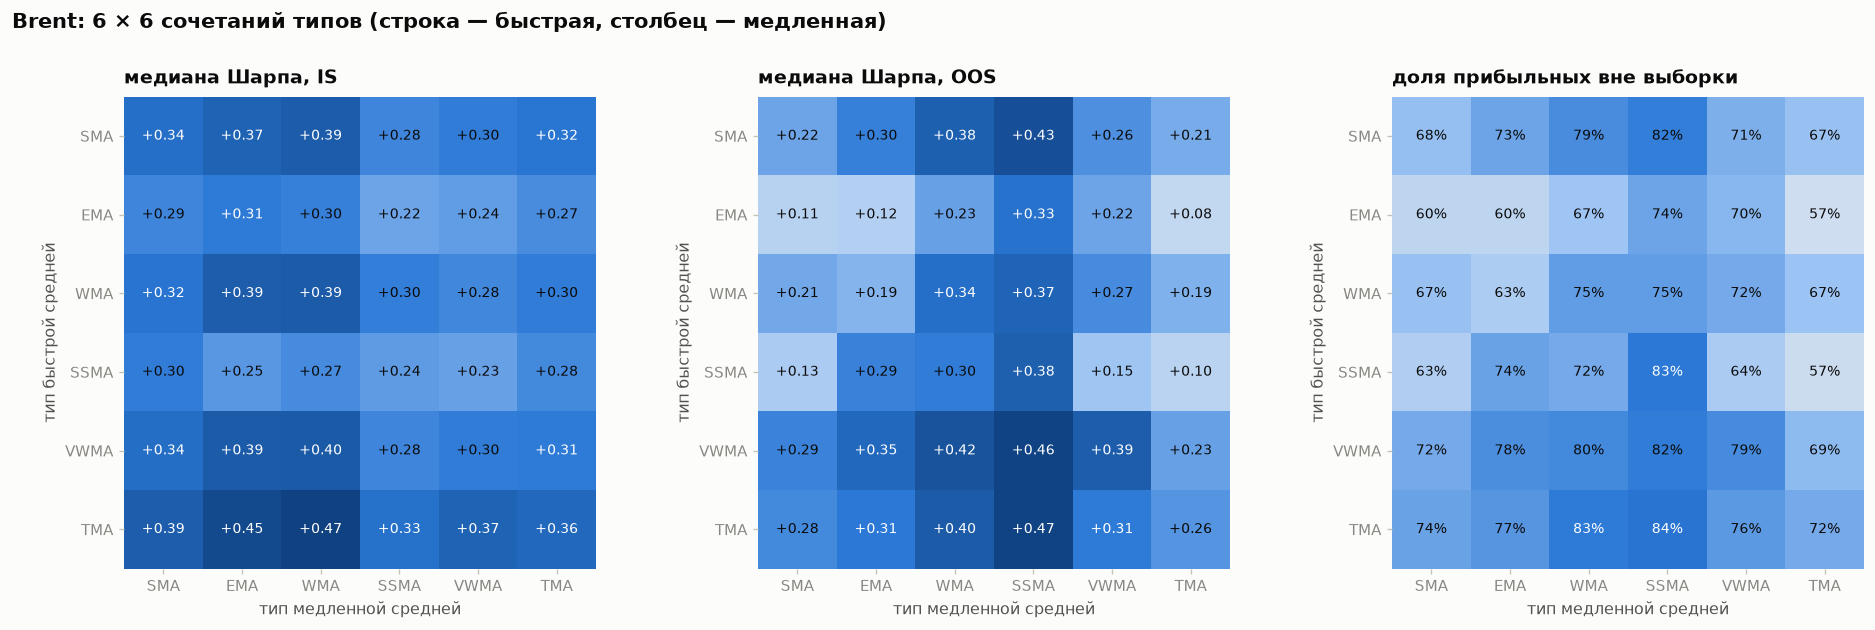

In [3]:
# 2. Все 36 сочетаний типов средних. Медиана по всем периодам, обоим методам и
#    выходам; слева — in-sample, справа — out-of-sample. Цвет — знак и сила,
#    число в клетке — сама медиана, поэтому смысл не держится на цвете.
for t in TICKERS:
    fam = pd.read_csv(A / STAGE / t / "by_type_pair.csv")
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    m_is = fam.pivot(index="fast_type", columns="slow_type", values="median_sharpe_is").loc[TYPES, TYPES].to_numpy()
    m_oos = fam.pivot(index="fast_type", columns="slow_type", values="median_sharpe_oos").loc[TYPES, TYPES].to_numpy()
    m_pos = fam.pivot(index="fast_type", columns="slow_type", values="share_pos_oos").loc[TYPES, TYPES].to_numpy()
    norm = P.sym_norm(np.r_[m_is.ravel(), m_oos.ravel()], q=1.0)
    P.matrix6(axes[0], m_is, TYPES, TYPES, norm=norm, title="медиана Шарпа, IS")
    P.matrix6(axes[1], m_oos, TYPES, TYPES, norm=norm, title="медиана Шарпа, OOS")
    from matplotlib.colors import TwoSlopeNorm
    P.matrix6(axes[2], m_pos, TYPES, TYPES, norm=TwoSlopeNorm(0.5, 0.0, 1.0), title="доля прибыльных вне выборки",
              fmt="{:.0%}")
    fig.suptitle(f"{NAMES[t]}: 6 × 6 сочетаний типов (строка — быстрая, столбец — медленная)", x=0.01, ha="left",
                 color=P.INK, fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout(); plt.show()


## 3. Модели выхода

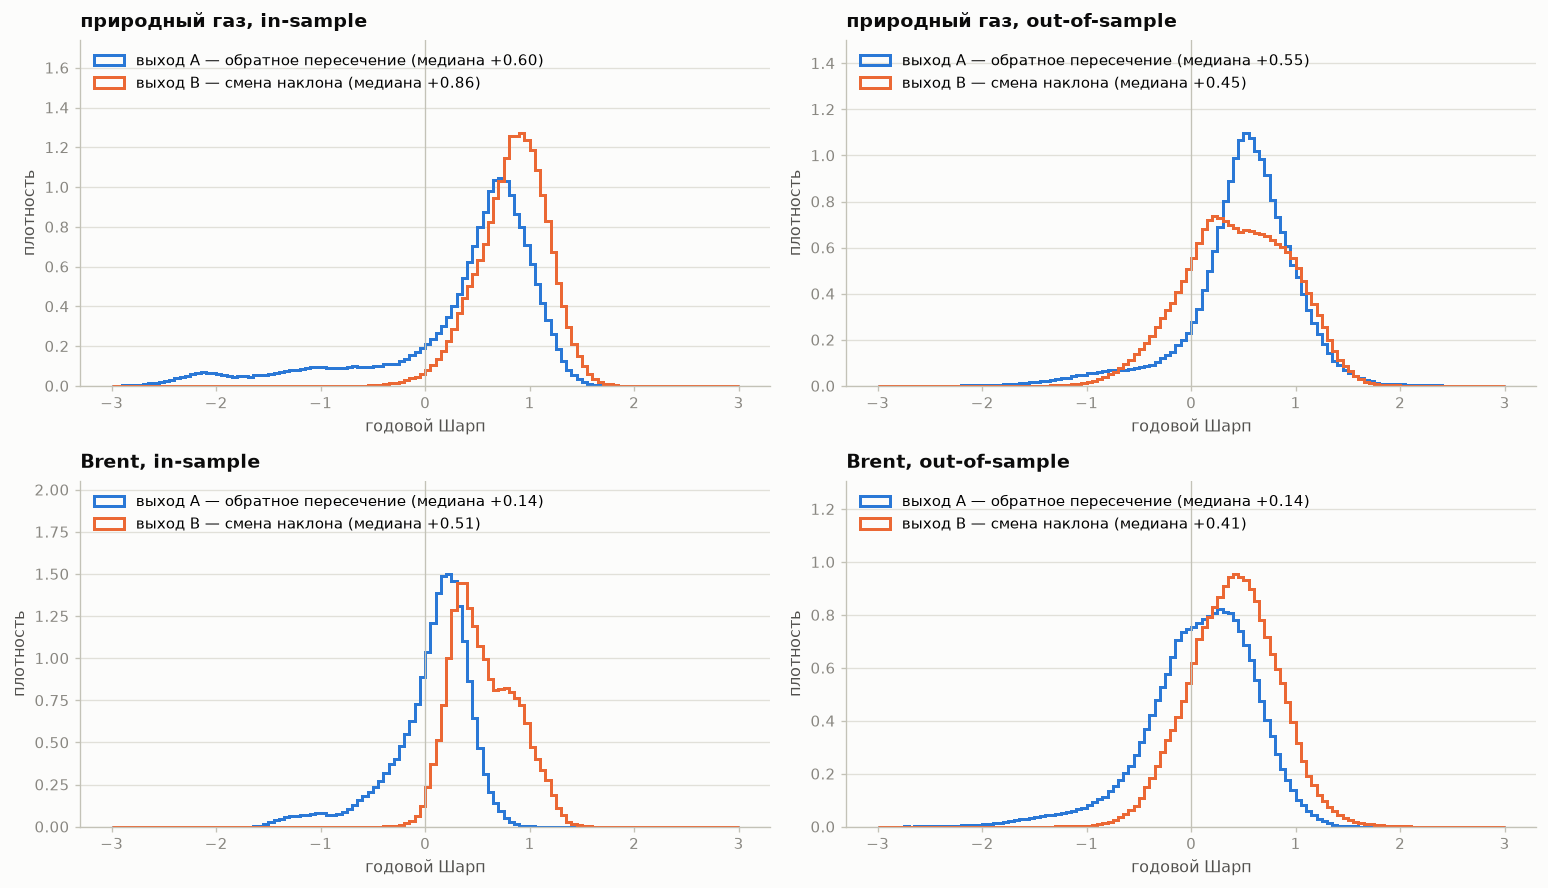

,NG,BR
exit_B_minus_A_sharpe_m_is_median,0.155695,0.363341
exit_B_minus_A_sharpe_m_is_share_B_better,0.674170,0.956458
exit_B_minus_A_sharpe_m_oos_median,-0.124288,0.245355
exit_B_minus_A_sharpe_m_oos_share_B_better,0.424459,0.737895
exit_B_minus_A_pnl_is_median,378.599976,872.600037
exit_B_minus_A_pnl_is_share_B_better,0.889833,0.977948
exit_B_minus_A_pnl_oos_median,-70.700012,181.500000
exit_B_minus_A_pnl_oos_share_B_better,0.379955,0.774927


In [4]:
# 3. Модели выхода: распределения Шарпа всех конфигураций (одна серия — один
#    выход, слоты 1 и 2), отдельно IS и OOS.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
bins = np.linspace(-3, 3, 121)
for row, t in enumerate(TICKERS):
    for col, per in enumerate(("is", "oos")):
        c = np.asarray(cube(t, f"sharpe_m_{per}"))
        ax = axes[row, col]
        P.frame(ax, f"{NAMES[t]}, {'in-sample' if per == 'is' else 'out-of-sample'}", xlabel="годовой Шарп",
                ylabel="плотность")
        P.step_hist(ax, {"выход A — обратное пересечение": c[:, :, :, 0].ravel(),
                         "выход B — смена наклона": c[:, :, :, 1].ravel()}, bins)
plt.tight_layout(); plt.show()
pd.DataFrame({t: {k: v for k, v in res[t].items() if k.startswith("exit_B_minus_A")} for t in TICKERS})


## 4. Методы нейтральной зоны

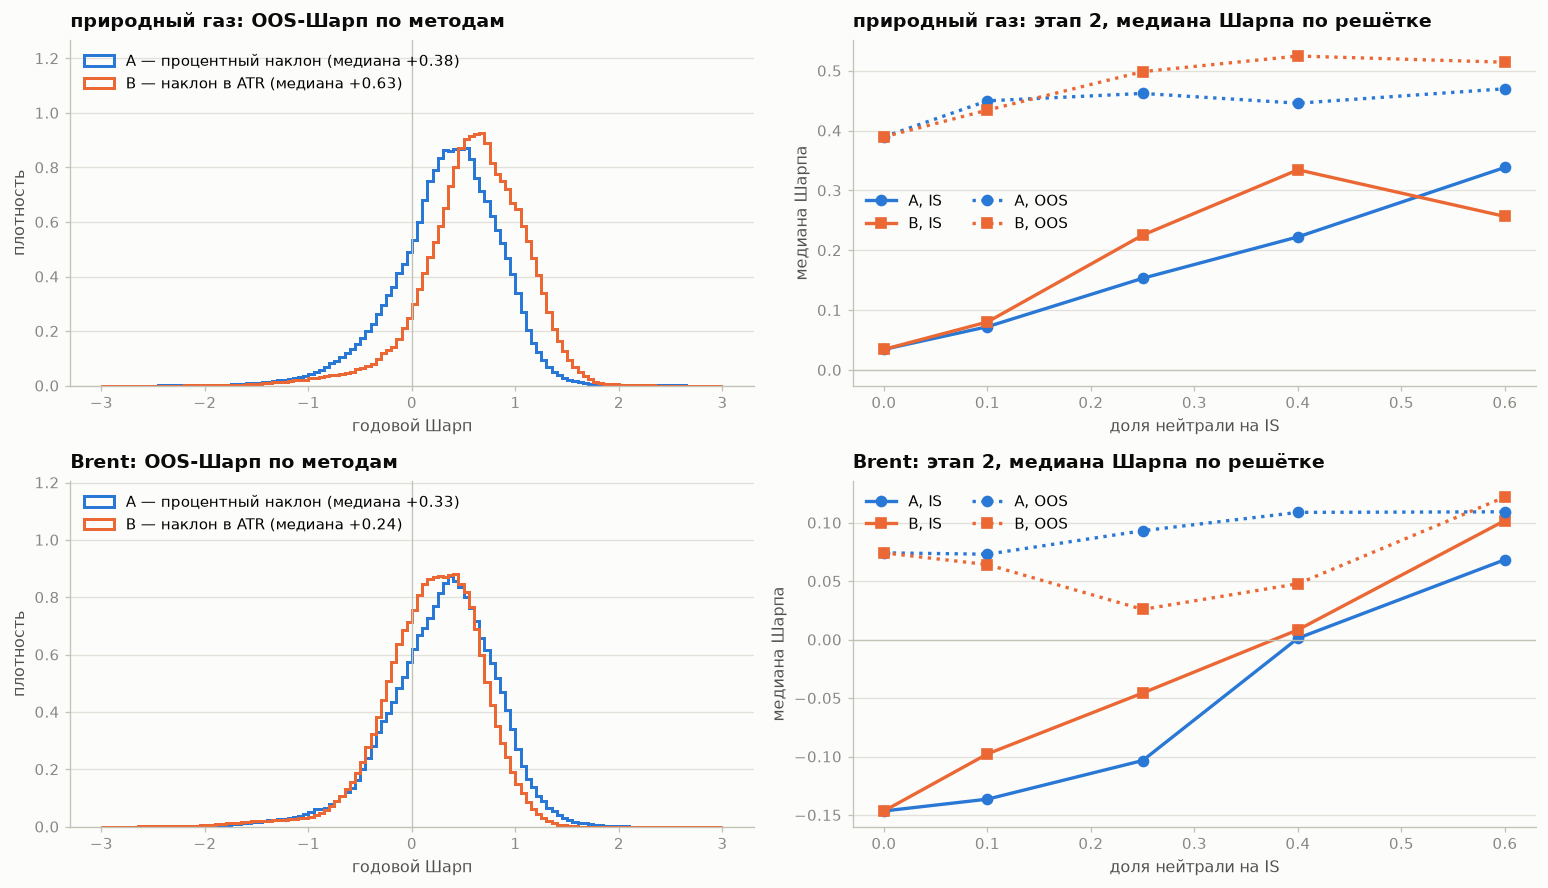

In [5]:
# 4. Методы нейтральной зоны A (процент) и B (ATR). Слева — распределения на
#    полной сетке; справа — этап 2: медиана IS- и OOS-Шарпа по решётке для
#    каждой пары (k, доля нейтрали), метод B — при лучшем по IS периоде ATR.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
bins = np.linspace(-3, 3, 121)
for row, t in enumerate(TICKERS):
    c = np.asarray(cube(t, "sharpe_m_oos"))
    ax = axes[row, 0]
    P.frame(ax, f"{NAMES[t]}: OOS-Шарп по методам", xlabel="годовой Шарп", ylabel="плотность")
    P.step_hist(ax, {"A — процентный наклон": c[0].ravel(), "B — наклон в ATR": c[1].ravel()}, bins)
    ax = axes[row, 1]
    mp_path = A / "stage2" / t / "method_pairs.csv"
    if not mp_path.exists():
        ax.axis("off"); continue
    mp = pd.read_csv(mp_path)
    P.frame(ax, f"{NAMES[t]}: этап 2, медиана Шарпа по решётке", xlabel="доля нейтрали на IS", ylabel="медиана Шарпа")
    for (lab, col, mk_) in (("A, IS", "A_is", "o"), ("B, IS", "B_is", "s"), ("A, OOS", "A_oos", "o"), ("B, OOS", "B_oos", "s")):
        g = mp.groupby("coverage")[col].median()
        ax.plot(g.index, g.values, marker=mk_, color=P.S1 if lab.startswith("A") else P.S2,
                linestyle="-" if "IS" in lab else ":", label=lab)
    ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.legend(ncol=2)
plt.tight_layout(); plt.show()


### 4б. Период определения наклона

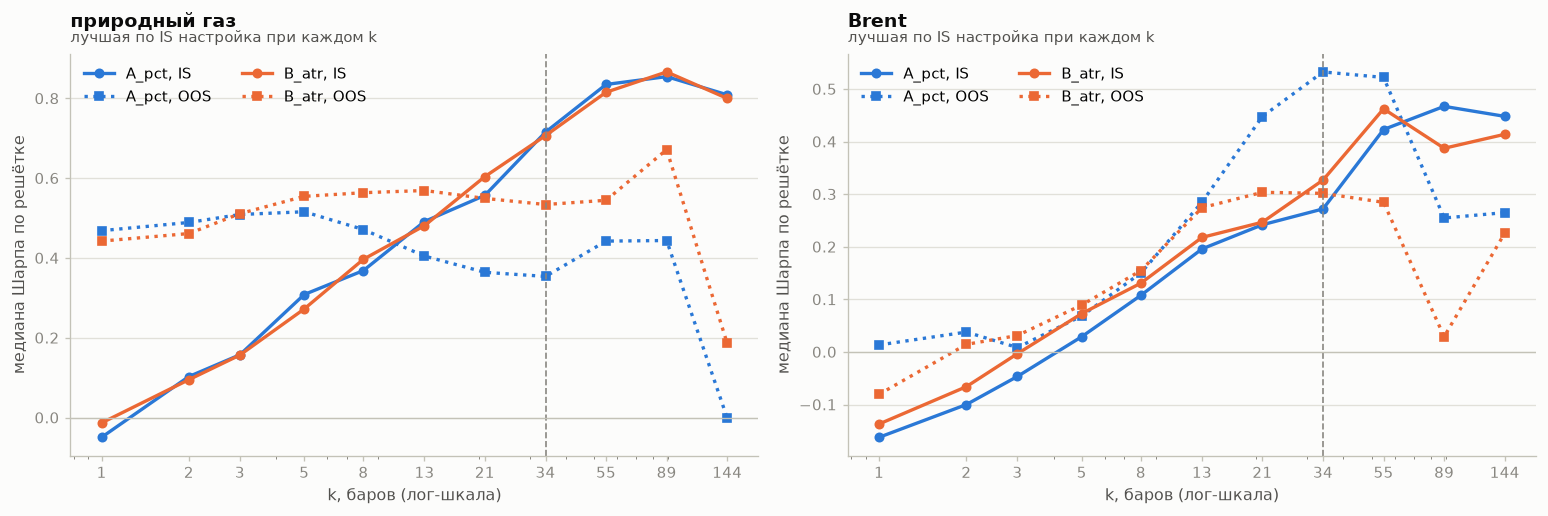

In [6]:
# 4б. Период определения наклона k — самый сильный параметрический эффект.
#    Лучшая по IS настройка (доля нейтрали, ATR) при каждом k на решётке
#    этапа 2 и её продлении (этап 2б, k = 55, 89, 144). Пунктир — граница
#    исходной сетки k: оптимум сначала оказался на ней, продление его нашло.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=False)
for ax, t in zip(axes, TICKERS):
    parts = [pd.read_csv(A / s / t / "settings.csv") for s in ("stage2", "stage2b") if (A / s / t / "settings.csv").exists()]
    s2 = pd.concat(parts)
    P.frame(ax, NAMES[t], "лучшая по IS настройка при каждом k", xlabel="k, баров (лог-шкала)",
            ylabel="медиана Шарпа по решётке")
    for m, c_ in (("A_pct", P.S1), ("B_atr", P.S2)):
        best = s2[s2["method"] == m].sort_values("median_sharpe_is").groupby("k").tail(1).sort_values("k")
        ax.plot(best["k"], best["median_sharpe_is"], color=c_, marker="o", markersize=5, label=f"{m}, IS")
        ax.plot(best["k"], best["median_sharpe_oos"], color=c_, marker="s", markersize=5, linestyle=":",
                label=f"{m}, OOS")
    ax.set_xscale("log"); ax.set_xticks([1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144])
    ax.set_xticklabels(["1", "2", "3", "5", "8", "13", "21", "34", "55", "89", "144"])
    ax.axvline(34, color=P.MUTED, linewidth=1.0, linestyle="--")
    ax.axhline(0, color=P.AXIS, linewidth=0.8)
    ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.show()


## 5. Карты устойчивости параметров

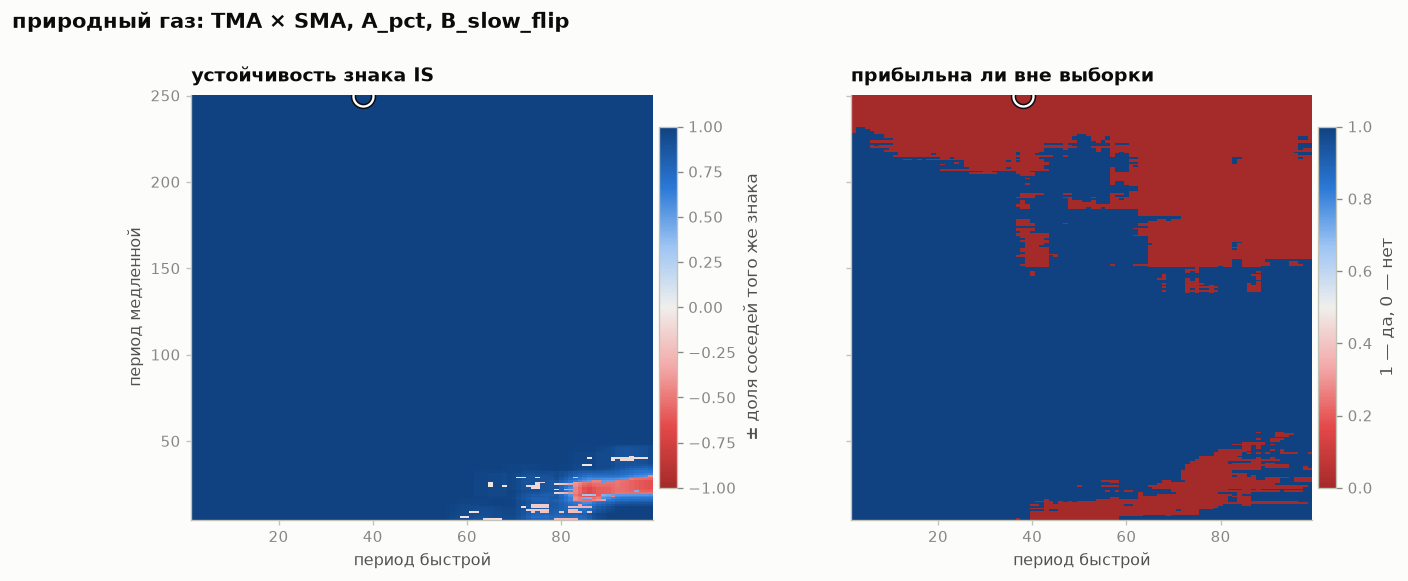

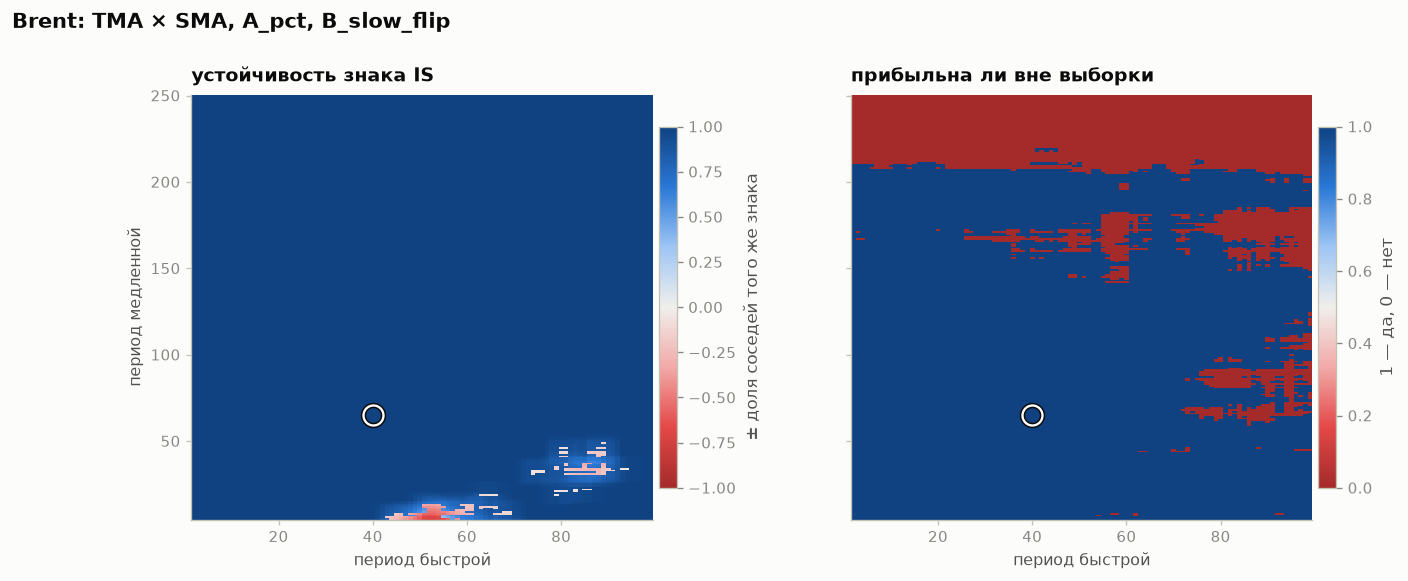

In [7]:
# 5. Карты устойчивости: доля соседей (±3 быстрой, ±7 медленной) с тем же
#    знаком IS-Шарпа. 1 — вся окрестность согласна, 0.5 — монетка. Рядом —
#    доля прибыльных вне выборки по той же сетке: совпадают ли области.
from matplotlib.colors import Normalize
for t in TICKERS:
    pk = picks[t].query("scope == 'global' and rule == 'R3_plateau'").iloc[0]
    mi = ["A_pct", "B_atr"].index(pk["method"]); ei = ["A_fast_cross", "B_slow_flip"].index(pk["exit"])
    si, fi = TYPES.index(pk["slow_type"]), TYPES.index(pk["fast_type"])
    stab = np.asarray(cube(t, "stability_is")[mi, si, :, ei, fi, :])
    sh_is = np.asarray(cube(t, "sharpe_m_is")[mi, si, :, ei, fi, :])
    oos_pos = (np.asarray(cube(t, "pnl_oos")[mi, si, :, ei, fi, :]) > 0).astype(float)
    signed = np.where(sh_is > 0, stab, -stab)            # синий — устойчиво прибыльно, красный — устойчиво убыточно
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    from matplotlib.colors import TwoSlopeNorm
    im = P.heatmap(axes[0], signed, FAST, SLOW, norm=TwoSlopeNorm(0, -1, 1), title="устойчивость знака IS",
                   xlabel="период быстрой", ylabel="период медленной", mark=(pk["fast_period"], pk["slow_period"]))
    fig.colorbar(im, ax=axes[0], shrink=0.85, pad=0.01).set_label("± доля соседей того же знака", color=P.INK_2)
    im2 = P.heatmap(axes[1], oos_pos, FAST, SLOW, norm=TwoSlopeNorm(0.5, 0, 1), title="прибыльна ли вне выборки",
                    xlabel="период быстрой", mark=(pk["fast_period"], pk["slow_period"]))
    fig.colorbar(im2, ax=axes[1], shrink=0.85, pad=0.01).set_label("1 — да, 0 — нет", color=P.INK_2)
    fig.suptitle(f"{NAMES[t]}: {pk['fast_type']} × {pk['slow_type']}, {pk['method']}, {pk['exit']}",
                 x=0.01, ha="left", color=P.INK, fontsize=12.5, fontweight="bold", y=1.03)
    plt.show()


## 6. Кривые накопленного PnL

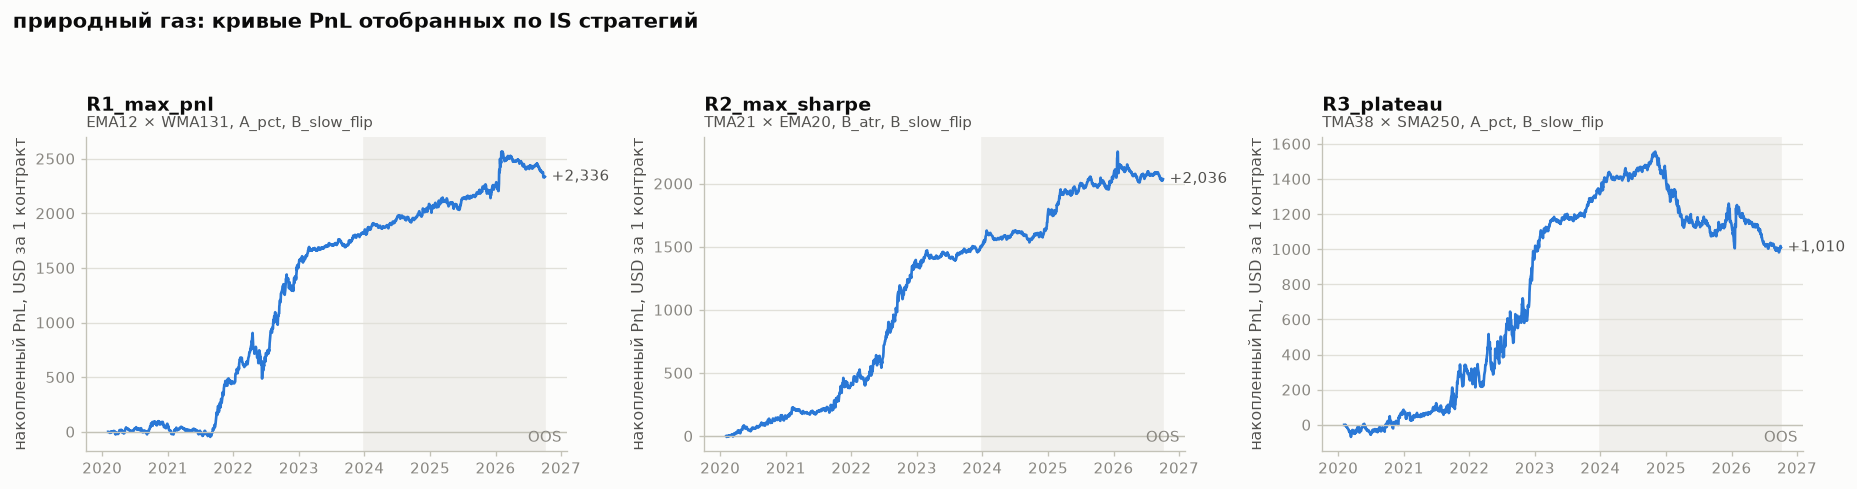

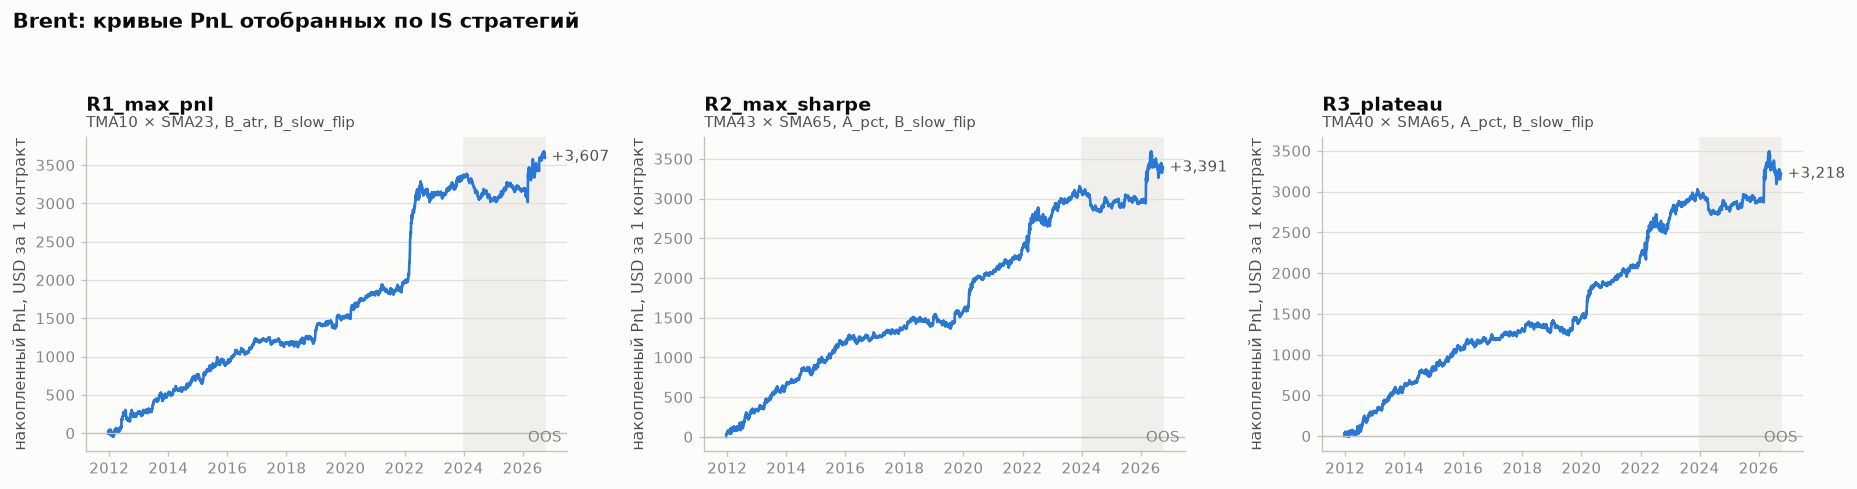

In [8]:
# 6. Накопленный PnL отобранных стратегий (VectorBT, переоценка открытой
#    позиции). Каждая панель — одно правило отбора; серый фон — out-of-sample.
for t in TICKERS:
    fin = json.loads((A / STAGE / t / "finalists.json").read_text())
    glob = [f for f in fin if f["scope"] == "global"]
    fig, axes = plt.subplots(1, len(glob), figsize=(5.2 * len(glob), 3.8), sharey=False)
    for ax, f in zip(np.atleast_1d(axes), glob):
        eq = pd.read_parquet(A / STAGE / t / "finalists" / f"cfg{f['grid_config']}_equity.parquet")["cum_pnl_usd"]
        oos0 = pd.Timestamp("2024-01-01")
        P.frame(ax, f"{f['rule']}", f"{f['config']['fast_type']}{f['config']['fast_period']} × "
                f"{f['config']['slow_type']}{f['config']['slow_period']}, {f['config']['method']}, {f['config']['exit']}",
                ylabel="накопленный PnL, USD за 1 контракт")
        ax.axvspan(oos0, eq.index[-1], color=P.NEUTRAL, zorder=0)
        ax.plot(eq.index, eq.values, color=P.S1, linewidth=1.6)
        ax.axhline(0, color=P.AXIS, linewidth=0.8)
        ax.annotate(f"{eq.iloc[-1]:+,.0f}", xy=(eq.index[-1], eq.iloc[-1]), xytext=(4, 0),
                    textcoords="offset points", va="center", color=P.INK_2, fontsize=9)
        ax.text(0.99, 0.03, "OOS", transform=ax.transAxes, ha="right", color=P.MUTED, fontsize=9)
    fig.suptitle(f"{NAMES[t]}: кривые PnL отобранных по IS стратегий", x=0.01, ha="left", color=P.INK,
                 fontsize=12.5, fontweight="bold", y=1.06)
    plt.tight_layout(); plt.show()


## 7. Распределения результатов сделок

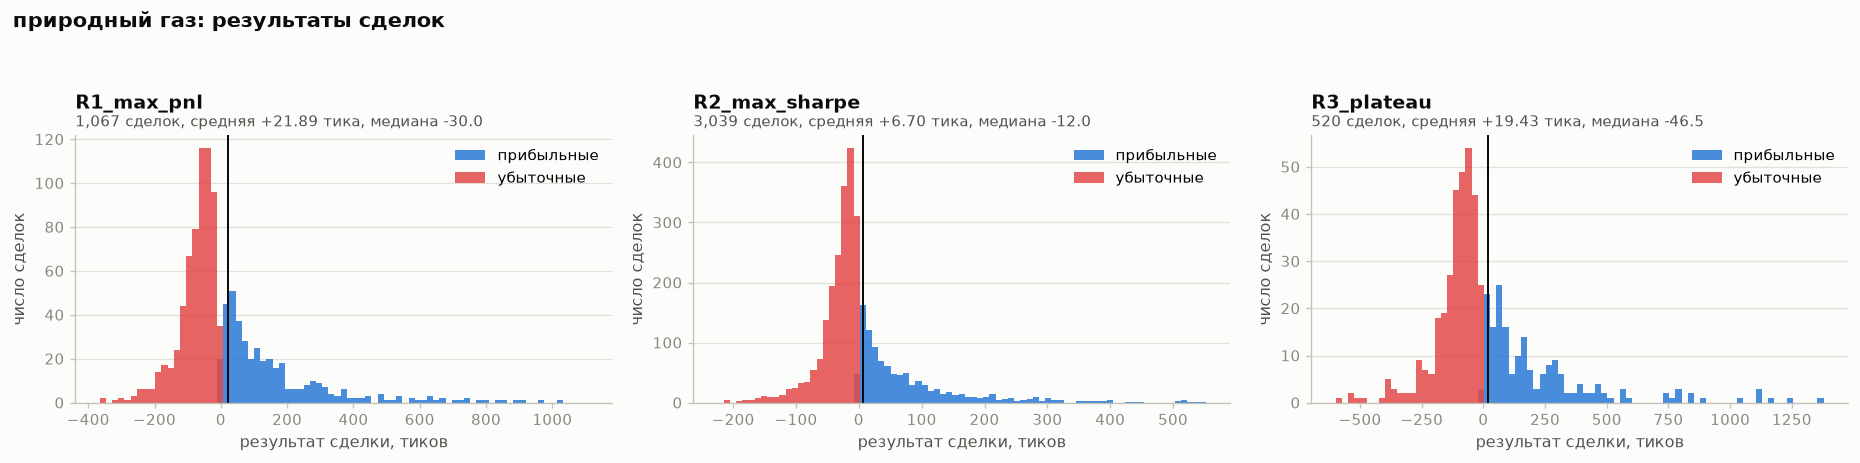

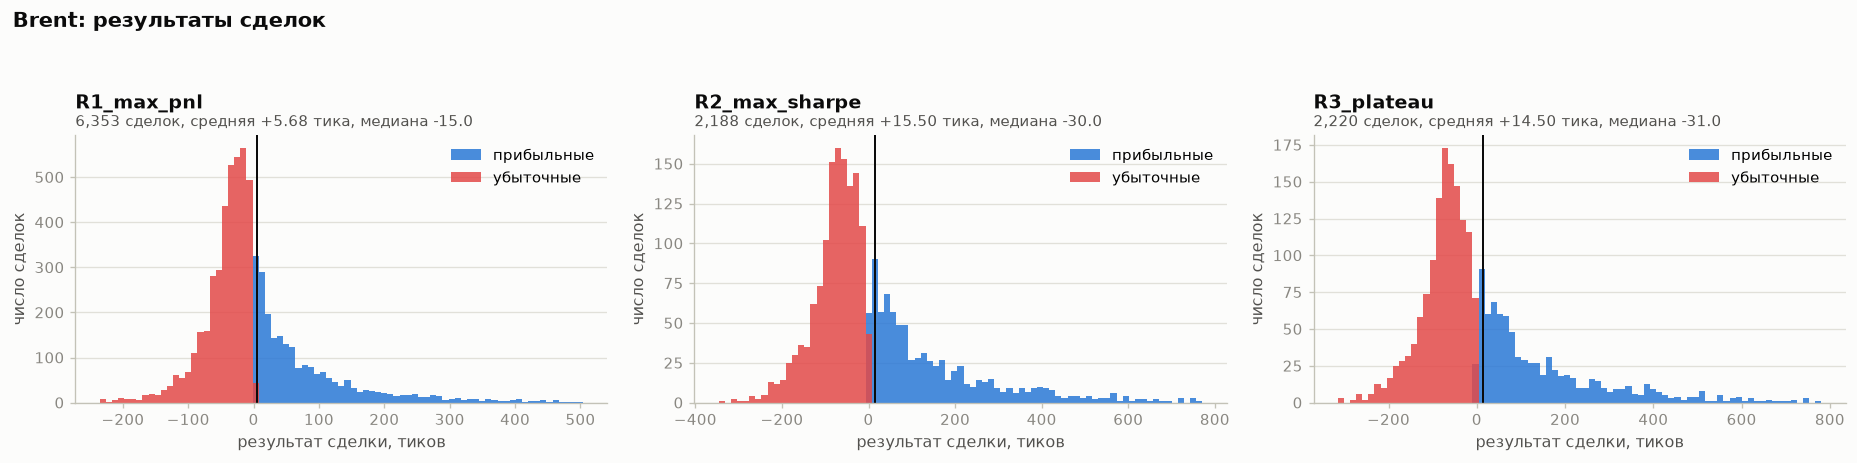

In [9]:
# 7. Распределения результатов сделок отобранных стратегий в тиках
#    (1 тик = 0.1 USD для обоих контрактов). Вертикаль — средняя сделка.
for t in TICKERS:
    fin = [f for f in json.loads((A / STAGE / t / "finalists.json").read_text()) if f["scope"] == "global"]
    fig, axes = plt.subplots(1, len(fin), figsize=(5.2 * len(fin), 3.6))
    tick_usd = meta[t]["tick"] * meta[t]["multiplier"]
    for ax, f in zip(np.atleast_1d(axes), fin):
        tr = pd.read_parquet(A / STAGE / t / "finalists" / f"cfg{f['grid_config']}_trades.parquet")
        x = tr["PnL"].to_numpy() / tick_usd
        lo, hi = np.percentile(x, [0.5, 99.5])
        P.frame(ax, f["rule"], f"{len(x):,} сделок, средняя {x.mean():+.2f} тика, медиана {np.median(x):+.1f}",
                xlabel="результат сделки, тиков", ylabel="число сделок")
        b = np.linspace(lo, hi, 80)
        ax.hist(x[x >= 0], bins=b, color=P.POS, alpha=0.85, label="прибыльные")
        ax.hist(x[x < 0], bins=b, color=P.NEG, alpha=0.85, label="убыточные")
        ax.axvline(x.mean(), color=P.INK, linewidth=1.2)
        ax.legend()
    fig.suptitle(f"{NAMES[t]}: результаты сделок", x=0.01, ha="left", color=P.INK, fontsize=12.5,
                 fontweight="bold", y=1.06)
    plt.tight_layout(); plt.show()


## 8. Сравнение инструментов

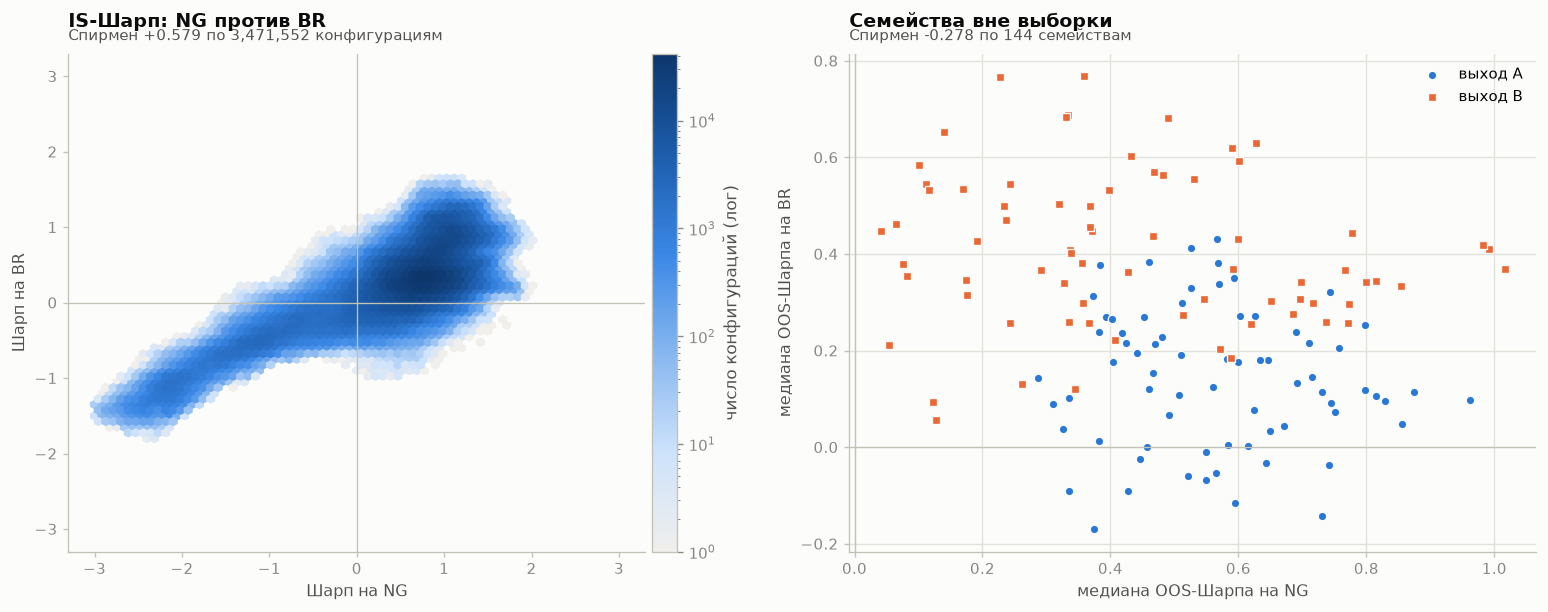

spearman_sharpe_m_is_NG_vs_BR          5.793814e-01
spearman_sharpe_m_oos_NG_vs_BR         1.439366e-01
spearman_plateau_sharpe_is_NG_vs_BR    6.125256e-01
share_pos_is_NG                        8.898591e-01
share_pos_is_BR                        8.267789e-01
share_pos_is_both                      8.106034e-01
share_pos_is_both_if_independent       7.357167e-01
share_pos_oos_NG                       8.419497e-01
share_pos_oos_BR                       7.188214e-01
share_pos_oos_both                     6.357376e-01
share_pos_oos_both_if_independent      6.052115e-01
n_pos_all_four                         1.940240e+06
n_pos_is_both                          2.814052e+06
share_oos_both_given_is_both           6.894826e-01
share_oos_both_unconditional           6.357376e-01
families_spearman_is                   6.824853e-01
families_spearman_oos                 -2.781770e-01
candidates                             2.500000e+01
candidates_oos_positive_both           2.500000e+01
dtype: float

In [10]:
# 8. Сравнение инструментов: одна и та же конфигурация на NG и BR.
#    Слева — IS-Шарп всех 3.47 млн конфигураций (плотность), справа — медианы
#    144 семейств (типы × выход × метод) вне выборки.
cm = json.loads((A / STAGE / "crossmarket.json").read_text())
fam = pd.read_csv(A / STAGE / "crossmarket_families.csv")
ng, br = np.asarray(cube("NG", "sharpe_m_is")).ravel(), np.asarray(cube("BR", "sharpe_m_is")).ravel()
ok = np.isfinite(ng) & np.isfinite(br)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
P.frame(ax, "IS-Шарп: NG против BR", f"Спирмен {cm['spearman_sharpe_m_is_NG_vs_BR']:+.3f} по {ok.sum():,} конфигурациям",
        xlabel="Шарп на NG", ylabel="Шарп на BR", grid_axis=None)
hb = ax.hexbin(ng[ok], br[ok], gridsize=70, bins="log", cmap=P.SEQUENTIAL, mincnt=1, extent=(-3, 3, -3, 3))
ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.axvline(0, color=P.AXIS, linewidth=0.8)
fig.colorbar(hb, ax=ax, pad=0.01).set_label("число конфигураций (лог)", color=P.INK_2)
ax = axes[1]
P.frame(ax, "Семейства вне выборки", f"Спирмен {cm['families_spearman_oos']:+.3f} по 144 семействам",
        xlabel="медиана OOS-Шарпа на NG", ylabel="медиана OOS-Шарпа на BR", grid_axis="both")
for e, c_, m_ in (("A_fast_cross", P.S1, "o"), ("B_slow_flip", P.S2, "s")):
    d = fam[fam["exit"] == e]
    ax.scatter(d["med_oos_NG"], d["med_oos_BR"], s=26, color=c_, marker=m_, edgecolor=P.SURFACE, linewidth=0.8,
               label=f"выход {e[0]}")
ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.axvline(0, color=P.AXIS, linewidth=0.8); ax.legend()
plt.tight_layout(); plt.show()
pd.Series({k: v for k, v in cm.items() if not isinstance(v, (list, dict))})


## 9. In-sample против out-of-sample

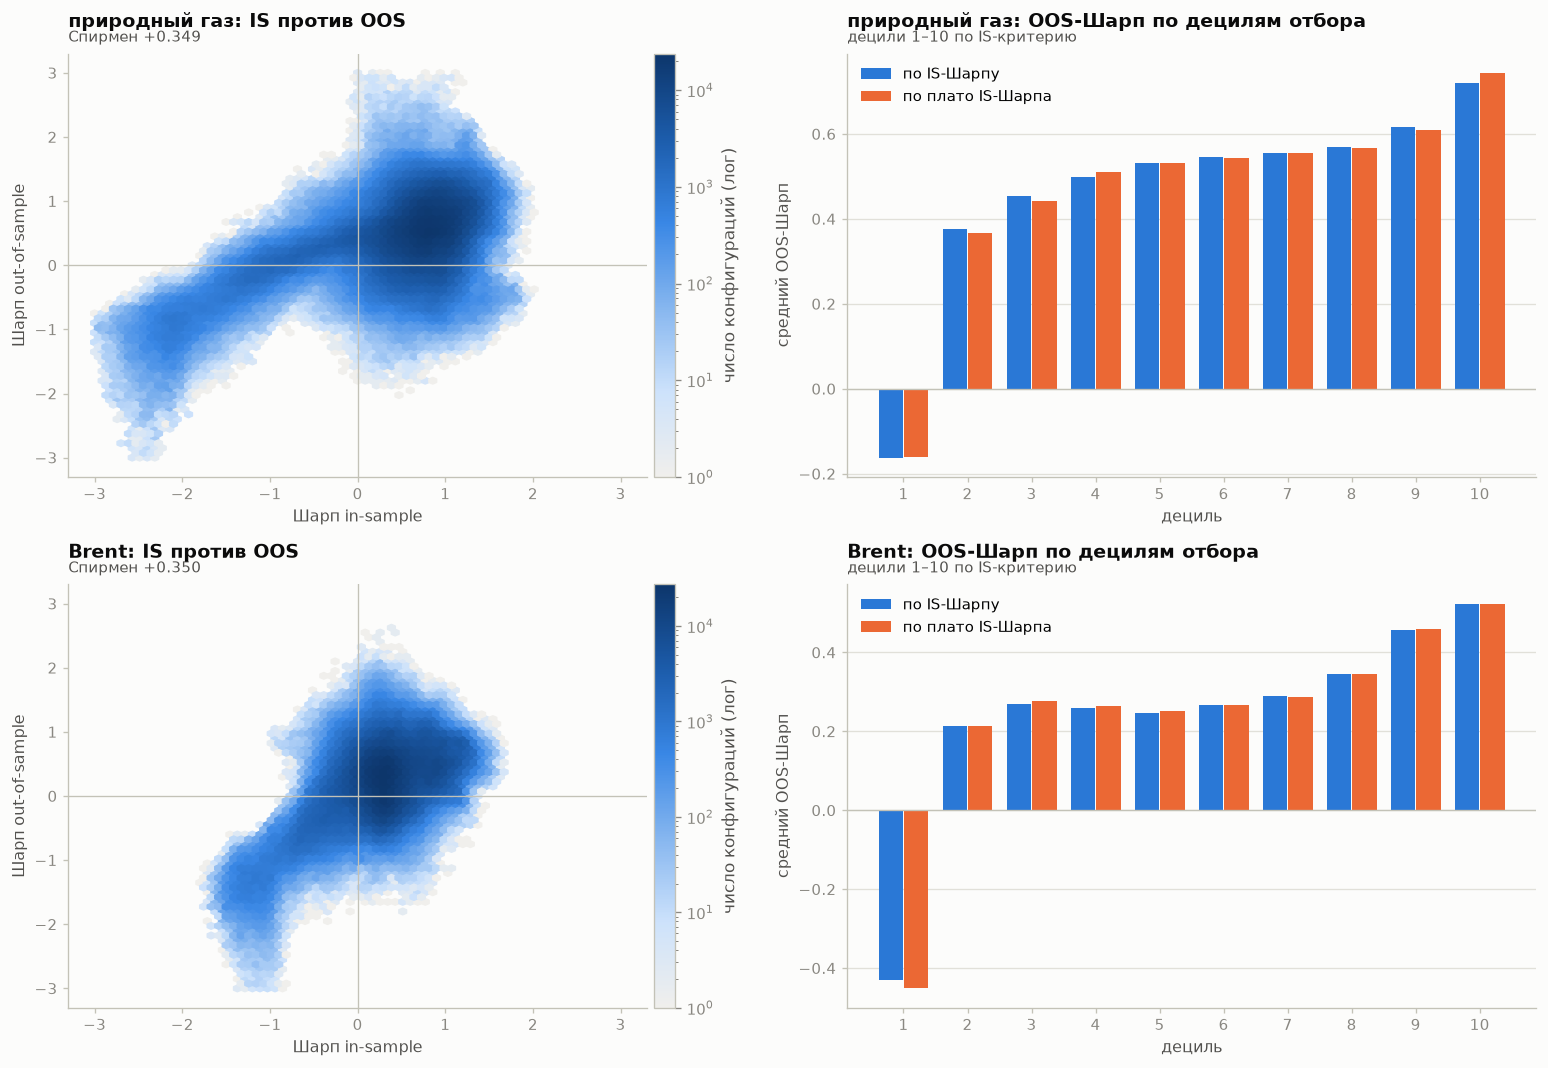

In [11]:
# 9. In-sample против out-of-sample на всей сетке. Если отбор по IS работает,
#    верхние децили IS должны давать лучший OOS; плоская или падающая лесенка
#    означает, что IS-результат не несёт информации о будущем.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, t in enumerate(TICKERS):
    a, b = np.asarray(cube(t, "sharpe_m_is")).ravel(), np.asarray(cube(t, "sharpe_m_oos")).ravel()
    ok = np.isfinite(a) & np.isfinite(b)
    ax = axes[row, 0]
    P.frame(ax, f"{NAMES[t]}: IS против OOS", f"Спирмен {res[t]['spearman_is_oos_sharpe']:+.3f}",
            xlabel="Шарп in-sample", ylabel="Шарп out-of-sample", grid_axis=None)
    hb = ax.hexbin(a[ok], b[ok], gridsize=70, bins="log", cmap=P.SEQUENTIAL, mincnt=1, extent=(-3, 3, -3, 3))
    ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.axvline(0, color=P.AXIS, linewidth=0.8)
    fig.colorbar(hb, ax=ax, pad=0.01).set_label("число конфигураций (лог)", color=P.INK_2)
    d1 = pd.read_csv(A / STAGE / t / "deciles_is_oos.csv"); d2 = pd.read_csv(A / STAGE / t / "deciles_plateau_oos.csv")
    ax = axes[row, 1]
    P.frame(ax, f"{NAMES[t]}: OOS-Шарп по децилям отбора", "децили 1–10 по IS-критерию", xlabel="дециль",
            ylabel="средний OOS-Шарп")
    x = np.arange(1, 11)
    ax.bar(x - 0.2, d1["oos_sharpe"], width=0.38, color=P.S1, label="по IS-Шарпу")
    ax.bar(x + 0.2, d2["oos_sharpe"], width=0.38, color=P.S2, label="по плато IS-Шарпа")
    ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.set_xticks(x); ax.legend()
plt.tight_layout(); plt.show()


## Дополнительно: walk-forward и PBO

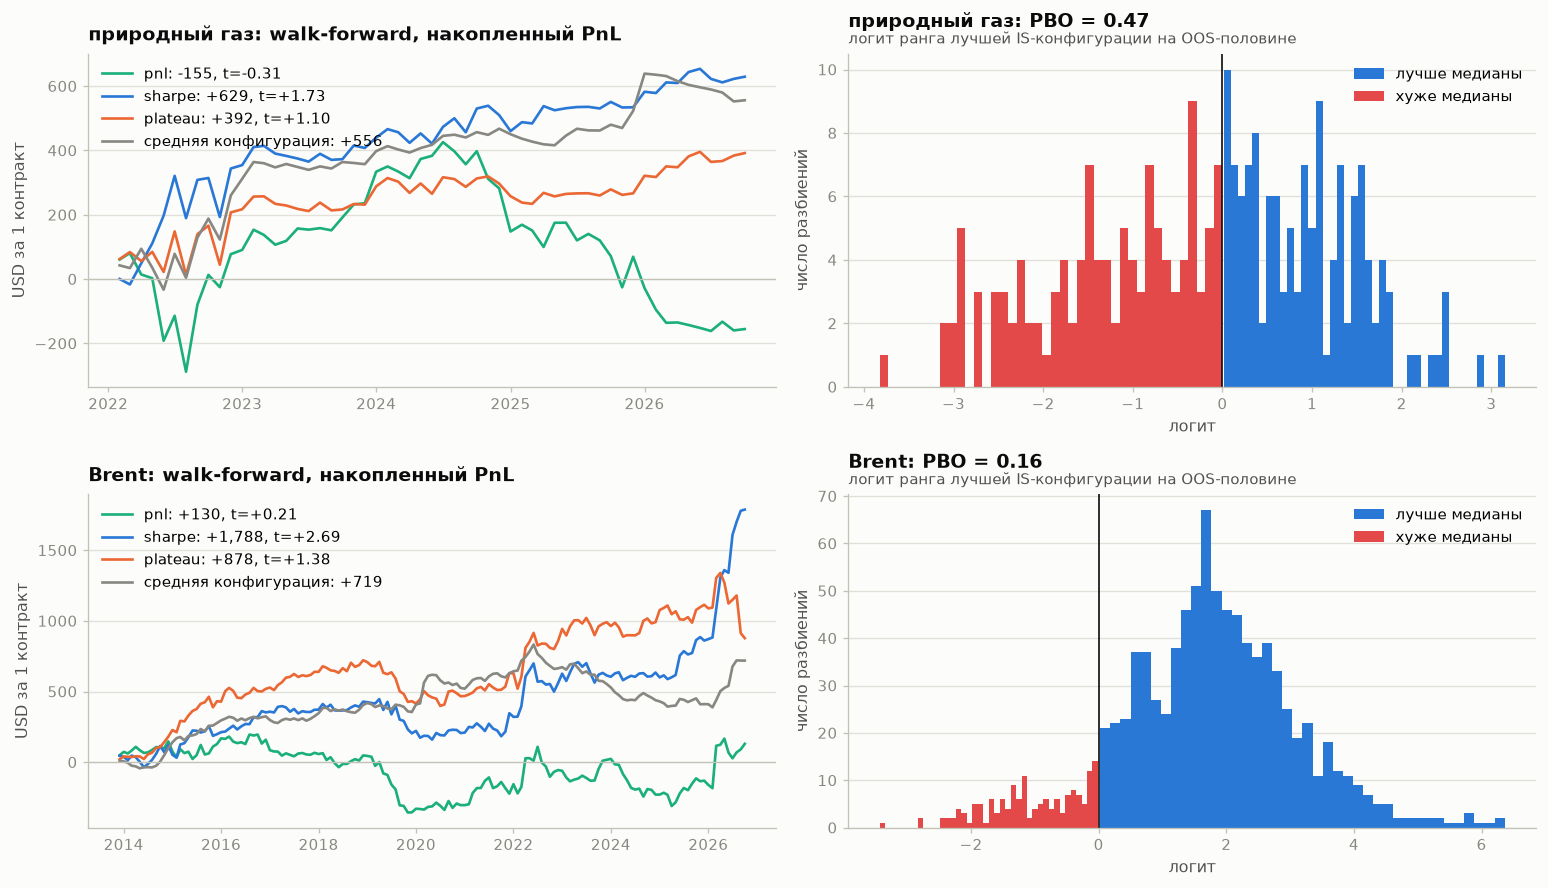

In [12]:
# Дополнительно: walk-forward с переоптимизацией по всей сетке и распределение
# логитов PBO. WF: окно обучения 24 месяца, тест 3 месяца, шаг 3 месяца.
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for row, t in enumerate(TICKERS):
    ax = axes[row, 0]
    months = pd.PeriodIndex(meta[t]["months"], freq="M")
    P.frame(ax, f"{NAMES[t]}: walk-forward, накопленный PnL", ylabel="USD за 1 контракт")
    for crit, c_ in (("pnl", P.S3), ("sharpe", P.S1), ("plateau", P.S2)):
        m = np.load(A / STAGE / t / f"wf_{crit}_months.npy")
        x = months[-len(m):].to_timestamp()
        wf = res[t]["walk_forward"][crit]
        ax.plot(x, np.cumsum(m), color=c_, linewidth=1.6, label=f"{crit}: {wf['total_pnl']:+,.0f}, t={wf['t_stat']:+.2f}")
    avg = np.load(A / STAGE / t / "avg_config_monthly.npy")[-len(m):]
    ax.plot(x, np.cumsum(avg), color=P.MUTED, linewidth=1.6,
            label=f"средняя конфигурация: {avg.sum():+,.0f}")
    ax.axhline(0, color=P.AXIS, linewidth=0.8); ax.legend(loc="upper left")
    ax = axes[row, 1]
    lg = np.load(A / STAGE / t / "pbo_full_logits.npy")
    P.frame(ax, f"{NAMES[t]}: PBO = {res[t]['pbo_full']['pbo']:.2f}", "логит ранга лучшей IS-конфигурации на OOS-половине",
            xlabel="логит", ylabel="число разбиений")
    ax.hist(lg[lg > 0], bins=40, color=P.POS, label="лучше медианы"); ax.hist(lg[lg <= 0], bins=40, color=P.NEG, label="хуже медианы")
    ax.axvline(0, color=P.INK, linewidth=1); ax.legend()
plt.tight_layout(); plt.show()
